# Shaping the long-run behaviour of an Interconnect loop

1. **The system as deployed.** Build the loop in Interconnect and run it. Where a run ends depends on where it started, so the loop has no single long-run behaviour.
2. **What Interconnect measures.** From passes of the graph, estimate how much each response mode stretches distances between states. This gives the contraction-on-average constant $C(\mu)$ of the Interconnect paper, eq. (12), for every law $\mu$ of the modes, and with it the set of laws under which the loop has a unique invariant measure.
3. **Shaping.** Inside that set, Algorithm 2 of *Shaping of invariant measures of parametrized stochastic dynamical systems* (Shafiei, Mareček, Shorten) looks for the law whose invariant measure is closest to a target.
4. **The shaped system.** Run the graph under the new law.

In [1]:
import os, sys
ROOT = os.path.abspath("../..")
for p in [ROOT, os.getcwd()]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy import stats

from humancompatible.interconnect.guarantees.contraction import mode_maps, mode_slopes
from humancompatible.interconnect.simulators.distribution import kernel_density_distribution

from ims_core import proj_Ar, simplex_grid
from opaque_system import OpaqueSim, grid_chain
from regions import (lipschitz_constants, average_lipschitz, contraction_on_average,
                     nondominated_rows, proj_Cr, projected_subgradient)
from shaping_system import empirical_measure

BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.titlesize": 11, "font.size": 10,
                     "lines.linewidth": 2})

## 1. The system as deployed

`r → A1 → F → C → P1 → A1`, with the reference $r=0.5$:

- `A1` forms the error $e=r-y$ from the agent's last answer $y$;
- `F` is a nonlinear filter, $F(e)=e-0.05\sin 2\pi e$;
- `C` is a neural-network controller with 16 hidden units;
- `P1` is an agent that answers $y\in(0,1)$. At every pass it draws one of three response modes with law $\mu$: **calm** pulls the answer towards $0.5$, **polarise low** pushes it away from $0.25$, **polarise high** pushes it away from $0.75$.

The state of the loop is the agent's answer $y_t$, the output of `P1`.

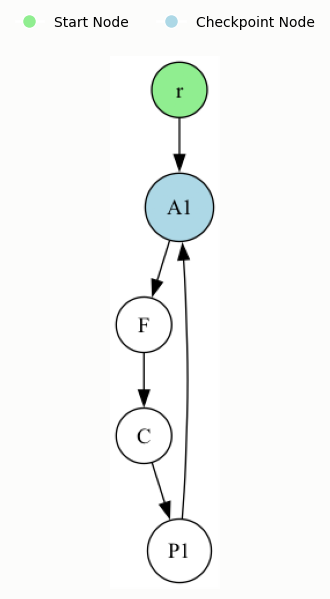

In [2]:
sim = OpaqueSim()
names = sim.mode_names
sim.plot.render_graph()

As deployed, the agent never uses the calm mode: $\mu_{\text{deployed}}=(0,\tfrac12,\tfrac12)$. The graph is run from nine starting answers, with `run(iterations, initial_outputs={"P1": y0})`.

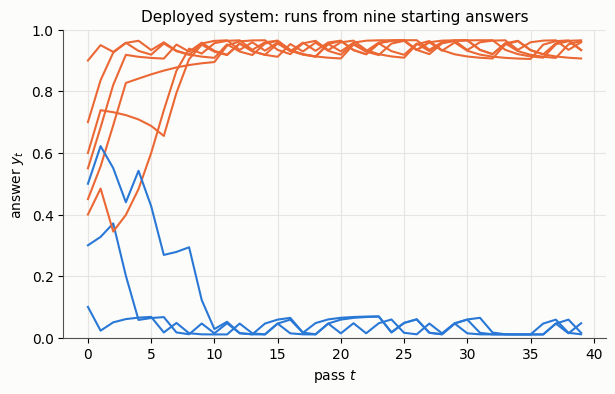

start 0.1 : answers stay in [0.011, 0.070] after pass 1000
start 0.3 : answers stay in [0.011, 0.070] after pass 1000
start 0.4 : answers stay in [0.903, 0.966] after pass 1000
start 0.45: answers stay in [0.903, 0.966] after pass 1000
start 0.5 : answers stay in [0.011, 0.070] after pass 1000
start 0.55: answers stay in [0.903, 0.966] after pass 1000
start 0.6 : answers stay in [0.903, 0.966] after pass 1000
start 0.7 : answers stay in [0.903, 0.966] after pass 1000
start 0.9 : answers stay in [0.903, 0.966] after pass 1000


In [3]:
mu_deployed = np.array([0.0, 0.5, 0.5])
starts = [0.1, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.9]

runs_deployed = [sim.simulate(mu_deployed, 5000, x0=y0)[0] for y0 in starts]

fig, ax = plt.subplots(figsize=(7, 4))
for y0, path in zip(starts, runs_deployed):
    ax.plot(path[:40], color=ORANGE if path[-1] > 0.5 else BLUE, lw=1.5)
ax.set(xlabel="pass $t$", ylabel="answer $y_t$", ylim=(0, 1),
       title="Deployed system: runs from nine starting answers")
plt.show()

for y0, path in zip(starts, runs_deployed):
    print(f"start {y0:<4}: answers stay in [{path[1000:].min():.3f}, {path[1000:].max():.3f}] after pass 1000")

Every run locks into one of two bands, near $0$ or near $1$, and never leaves it. Which band it is depends on the starting answer and, for starts near the middle, on the first few draws of the modes. The long-run distribution of the answers therefore differs from run to run, so the deployed loop has more than one invariant measure.

## 2. What Interconnect measures

One pass of the graph from a state $y$ with the agent's mode held at $i$ is a map $w_i(y)$. `mode_slopes` runs such passes with `run(1)` and differentiates each of them through the whole graph. The result is a table

$$D[j,i]=|w_i'(y_j)|,$$

one row per state, one column per mode. The states $y_j$ are those visited by short probing runs of the graph from eleven starting answers.

The table does not depend on $\mu$. For any law, eq. (12) of the Interconnect paper is

$$C(\mu)=\max_j\sum_i\mu_i\,D[j,i],$$

and $C(\mu)<1$ means the loop contracts on average and has a unique invariant measure. The maximum is over the visited states, so it is an estimate from below.

In [4]:
probe = np.concatenate([sim.simulate(np.ones(3) / 3, 200, x0=y0, seed=20 + k)[0]
                        for k, y0 in enumerate(np.linspace(0, 1, 11))])
D = mode_slopes(sim.system, "P1", probe, sim.m)

print(f"{len(probe)} visited states, table D of shape {D.shape}")
print(f"C(mu_deployed) = {contraction_on_average(mu_deployed, D):.3f}")

2211 visited states, table D of shape (2211, 3)
C(mu_deployed) = 1.354


Each point of the triangle below is a law $\mu$; a corner is a law that always uses one mode. The colour is $C(\mu)$. With a margin $r=0.9$, the laws inside the white line form the search region

$$\mathcal A_r=\{\mu:\ C(\mu)\le r\}.$$

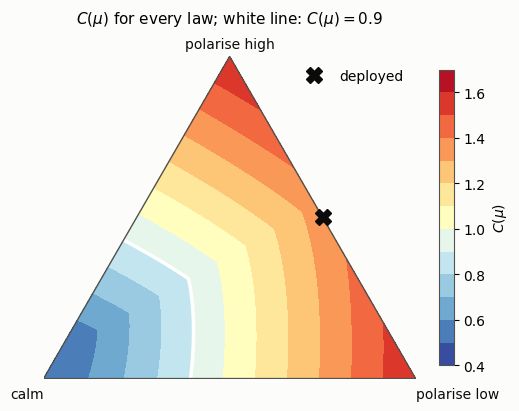

the search region covers 23% of all laws


In [5]:
r = 0.9
D_active = nondominated_rows(D)          # the rows that can attain the maximum in C(mu)
G = simplex_grid(3, 200)
C_grid = (D_active @ G.T).max(axis=0)

def to_xy(m):
    m = np.atleast_2d(m)
    return m[:, 1] + 0.5 * m[:, 2], np.sqrt(3) / 2 * m[:, 2]

tri = mtri.Triangulation(*to_xy(G))

def draw_simplex(ax):
    im = ax.tricontourf(tri, C_grid, levels=np.linspace(0.4, 1.7, 14), cmap="RdYlBu_r")
    ax.tricontour(tri, C_grid, levels=[r], colors="white", linewidths=2.5)
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3) / 2, 0], color=MUTED, lw=1)
    for (cx, cy), name, ha in zip([(0, 0), (1, 0), (0.5, np.sqrt(3) / 2)], names, ["right", "left", "center"]):
        ax.annotate(name, (cx, cy), xytext=(0, -14 if cy == 0 else 6), textcoords="offset points", ha=ha, color=INK)
    ax.set_aspect("equal"); ax.axis("off")
    return im

fig, ax = plt.subplots(figsize=(6, 4.8))
im = draw_simplex(ax)
ax.plot(*to_xy(mu_deployed), "X", color=INK, ms=11, label="deployed")
ax.legend(frameon=False, loc="upper right")
fig.colorbar(im, ax=ax, shrink=0.8, label="$C(\\mu)$")
ax.set_title(f"$C(\\mu)$ for every law; white line: $C(\\mu)={r}$", pad=24)
plt.show()
print(f"the search region covers {np.mean(C_grid <= r):.0%} of all laws")

## 3. Shaping

The target $\nu$ is $\mathrm{Beta}(10,10)$: answers concentrated around $0.5$. Algorithm 2 minimises the distance $J(\mu)=W_1(\nu,\pi_\mu)$ between the target and the invariant measure $\pi_\mu$, by projected subgradient steps that stay in $\mathcal A_r$. It starts from the law in $\mathcal A_r$ nearest to the deployed one.

Algorithm 2 works on a finite-state model of the loop. The model is the three maps $w_i$ tabulated on 801 states; `mode_maps` gets each of them with one batched `run(1)` pass.

nearest law in A_r : {'calm': 0.456, 'polarise low': 0.235, 'polarise high': 0.31},  C = 0.900,  J = 0.0522
shaped law         : {'calm': 0.602, 'polarise low': 0.216, 'polarise high': 0.183},  C = 0.788,  J = 0.0257


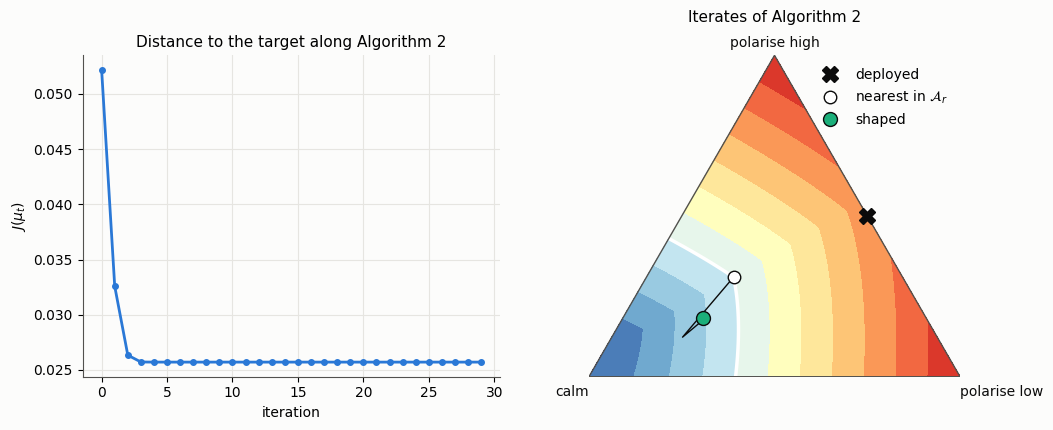

In [6]:
x = np.linspace(0, 1, 801)
chain = grid_chain(mode_maps(sim.system, "P1", x, sim.m), x)

def beta_target(a, b):
    e = np.concatenate([[0], (x[:-1] + x[1:]) / 2, [1]])
    p = np.diff(stats.beta(a, b).cdf(e))
    return p / p.sum()

nu = beta_target(10, 10)
project = lambda y: proj_Cr(y, D_active, r)
mu_nearest = project(mu_deployed)
res = projected_subgradient(chain, nu, mu_nearest, 300, project, gamma=0.3)
mu_shaped = res["best_mu"]

for label, mu, J in [("nearest law in A_r", mu_nearest, res["J"][0]), ("shaped law", mu_shaped, res["best_J"])]:
    print(f"{label:<19}: {dict(zip(names, np.round(mu, 3)))},  C = {contraction_on_average(mu, D):.3f},  J = {J:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].plot(res["J"][:30], "o-", color=BLUE, ms=4)
axes[0].set(xlabel="iteration", ylabel="$J(\\mu_t)$", title="Distance to the target along Algorithm 2")
draw_simplex(axes[1])
axes[1].plot(*to_xy(res["traj"]), color=INK, lw=1)
axes[1].plot(*to_xy(mu_deployed), "X", color=INK, ms=11, label="deployed")
axes[1].plot(*to_xy(mu_nearest), "o", color="white", mec=INK, ms=9, label="nearest in $\mathcal{A}_r$")
axes[1].plot(*to_xy(mu_shaped), "o", color=AQUA, mec=INK, ms=10, label="shaped")
axes[1].legend(frameon=False, loc="upper right")
axes[1].set_title("Iterates of Algorithm 2", pad=24)
fig.tight_layout(); plt.show()

## 4. The shaped system

The graph is run under the shaped law from the same nine starting answers as in Section 1.

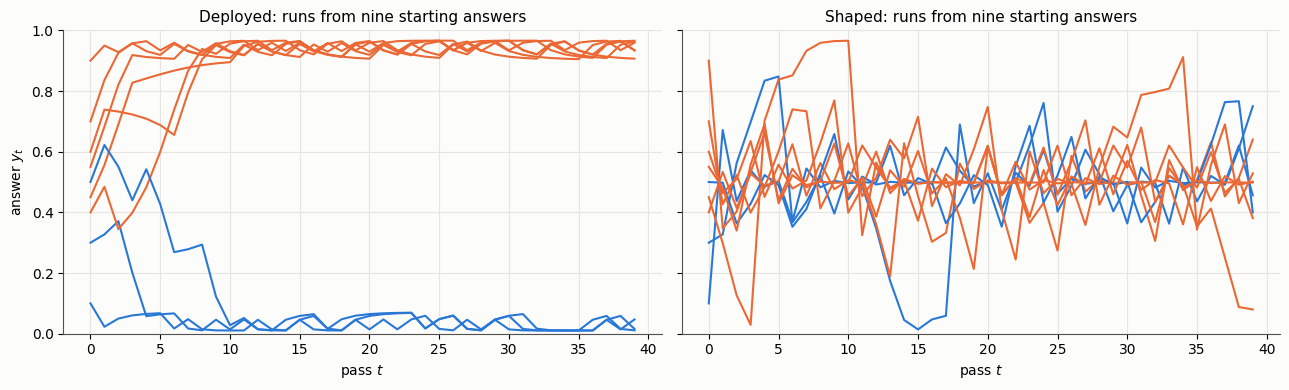

mean answer after pass 1000
start     deployed    shaped
0.1          0.033     0.502
0.3          0.035     0.504
0.4          0.941     0.496
0.45         0.942     0.504
0.5          0.034     0.505
0.55         0.942     0.502
0.6          0.942     0.501
0.7          0.943     0.502
0.9          0.943     0.505


In [7]:
runs_shaped = [sim.simulate(mu_shaped, 5000, x0=y0)[0] for y0 in starts]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, runs, title in [(axes[0], runs_deployed, "Deployed"), (axes[1], runs_shaped, "Shaped")]:
    for path, ref in zip(runs, runs_deployed):
        ax.plot(path[:40], color=ORANGE if ref[-1] > 0.5 else BLUE, lw=1.5)
    ax.set(xlabel="pass $t$", ylim=(0, 1), title=f"{title}: runs from nine starting answers")
axes[0].set_ylabel("answer $y_t$")
fig.tight_layout(); plt.show()

print("mean answer after pass 1000")
print(f"{'start':<8}{'deployed':>10}{'shaped':>10}")
for y0, dep, shp in zip(starts, runs_deployed, runs_shaped):
    print(f"{y0:<8}{dep[1000:].mean():>10.3f}{shp[1000:].mean():>10.3f}")

Under the shaped law every run moves over the same range, whatever its start: the loop forgets its starting answer.

The long-run distribution of the answers is estimated with Interconnect's kernel density estimator, `kernel_density_distribution`, from runs that start at two opposite answers and use independent draws of the modes. Three laws are compared: the deployed one, the nearest law in $\mathcal A_r$, and the shaped one.

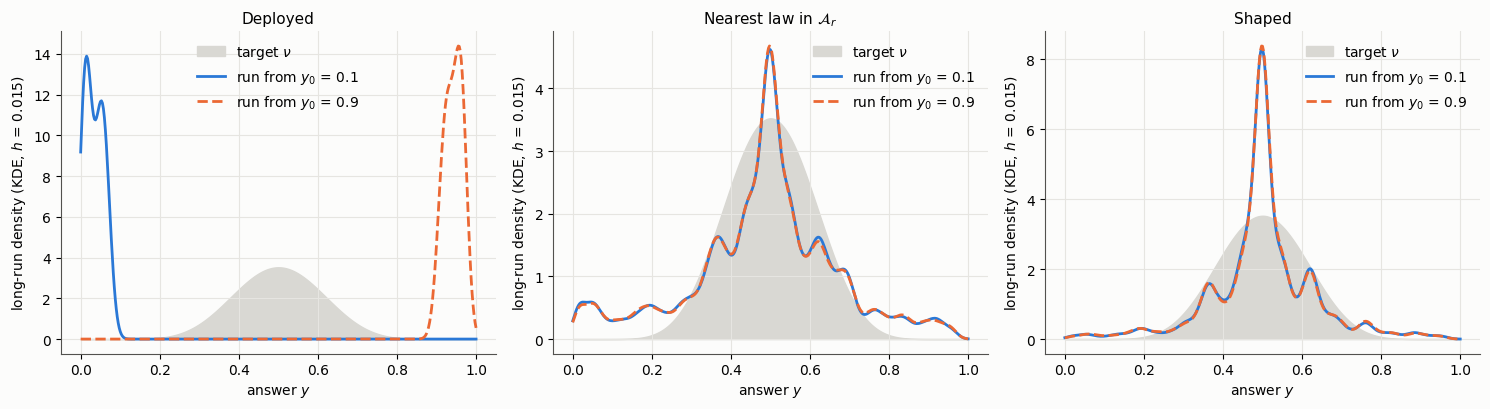

                                  deployed   nearest    shaped
C(mu)                                1.354     0.900     0.788
W1 between the two runs             0.9084    0.0013    0.0006
W1 to the target, run from 0.1      0.4661    0.0521    0.0256
W1 to the target, run from 0.9      0.4423    0.0511    0.0259


In [8]:
def long_run(mu, x0, seed, steps=60000, burn=1000):
    return sim.simulate(mu, steps, x0=x0, seed=seed)[0][burn:]

ends = [0.1, 0.9]
laws = [("Deployed", mu_deployed), ("Nearest law in $\\mathcal{A}_r$", mu_nearest), ("Shaped", mu_shaped)]
samples = [[long_run(mu, y0, seed=3 + k) for k, y0 in enumerate(ends)] for _, mu in laws]

y_plot = np.linspace(0, 1, 401)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (title, _), pair in zip(axes, laws, samples):
    ax.fill_between(y_plot, stats.beta(10, 10).pdf(y_plot), color="#d9d8d3", label="target $\\nu$")
    for path, y0, c, ls in zip(pair, ends, [BLUE, ORANGE], ["-", "--"]):
        ax.plot(y_plot, kernel_density_distribution(y_plot, path[::3], h=0.015), color=c, ls=ls,
                label=f"run from $y_0$ = {y0}")
    ax.set(xlabel="answer $y$", ylabel="long-run density (KDE, $h$ = 0.015)", title=title)
    ax.legend(frameon=False)
fig.tight_layout(); plt.show()

emps = [[empirical_measure(path, x) for path in pair] for pair in samples]
print(f"{'':<32}{'deployed':>10}{'nearest':>10}{'shaped':>10}")
print(f"{'C(mu)':<32}" + "".join(f"{contraction_on_average(mu, D):>10.3f}" for _, mu in laws))
print(f"{'W1 between the two runs':<32}" + "".join(f"{chain.w1(*pair):>10.4f}" for pair in emps))
for k, y0 in enumerate(ends):
    print(f"{'W1 to the target, run from ' + str(y0):<32}" + "".join(f"{chain.w1(pair[k], nu):>10.4f}" for pair in emps))
assert chain.w1(*emps[2]) < 0.01

## 5. Checks

- The slopes from `mode_slopes` against finite differences of `run(1)` passes.
- $C(\mu)$ from the visited states against $C(\mu)$ on a grid of 2001 states.
- The result of Algorithm 2 against a grid search over the laws in $\mathcal A_r$.
- The region of the shaping paper, $\{\mu:\sum_i\mu_iL_i\le r\}$ with $L_i=\max_jD[j,i]$, for comparison. It is contained in $\mathcal A_r$; using $C(\mu)$ in Algorithm 2 is our extension of the paper.

In [9]:
xg = np.linspace(0, 1, 2001)
Dg = mode_slopes(sim.system, "P1", xg, sim.m)
h = 1e-6
Dfd = np.abs(mode_maps(sim.system, "P1", xg + h, sim.m) - mode_maps(sim.system, "P1", xg - h, sim.m)).T / (2 * h)
print(f"max |autograd - finite difference| over 2001 states: {np.abs(Dg - Dfd).max():.1e}")
assert np.abs(Dg - Dfd).max() < 1e-6

for label, mu in [("deployed", mu_deployed), ("nearest", mu_nearest), ("shaped", mu_shaped)]:
    print(f"C(mu_{label}): visited states {contraction_on_average(mu, D):.4f}, grid {contraction_on_average(mu, Dg):.4f}")

G_C = G[C_grid <= r + 1e-12][::4]
J_grid = np.array([chain.w1(chain.stationary(m), nu) for m in G_C])
print(f"Algorithm 2: J = {res['best_J']:.4f};  grid search over {len(G_C)} laws in A_r: J = {J_grid.min():.4f}")
assert res["best_J"] <= J_grid.min() + 1e-3

ell = lipschitz_constants(D)
P_L = lambda y: proj_Ar(y, ell, r)
res_L = projected_subgradient(chain, nu, P_L(mu_deployed), 300, P_L, gamma=0.3)
print(f"region of the shaping paper: {np.mean(G @ ell <= r):.0%} of all laws, J = {res_L['best_J']:.4f};  "
      f"A_r: {np.mean(C_grid <= r):.0%}, J = {res['best_J']:.4f}")

max |autograd - finite difference| over 2001 states: 6.9e-10
C(mu_deployed): visited states 1.3540, grid 1.3540
C(mu_nearest): visited states 0.9000, grid 0.9000
C(mu_shaped): visited states 0.7881, grid 0.7881


Algorithm 2: J = 0.0257;  grid search over 1165 laws in A_r: J = 0.0257


region of the shaping paper: 13% of all laws, J = 0.0270;  A_r: 23%, J = 0.0257
